In [1]:
# Inventory Demand Forecasting Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Inventory Demand Forecasting Project")
print("Libraries imported successfully!")

Inventory Demand Forecasting Project
Libraries imported successfully!


In [3]:
import zipfile
import os

zip_path = "/content/train.csv.zip"  # Updated to the correct filename found in your environment
extract_path = "/content/sales_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")
print(os.listdir(extract_path))

ZIP file extracted successfully!
['train.csv']


In [4]:
import pandas as pd
import os

# Find CSV files inside the extracted folder
for root, dirs, files in os.walk("/content/sales_data"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/sales_data/train.csv


In [5]:
import pandas as pd

df = pd.read_csv("/content/sales_data/train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [6]:
# Check dataset information
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of unique stores:", df["store"].nunique())
print("Number of unique items:", df["item"].nunique())

print("\nDate range:")
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

print("\nSales statistics:")
display(df["sales"].describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB

Missing values in each column:
date     0
store    0
item     0
sales    0
dtype: int64

Number of unique stores: 10
Number of unique items: 50

Date range:
Start date: 2013-01-01
End date: 2017-12-31

Sales statistics:


,sales
count,913000.000000
mean,52.250287
std,28.801144
min,0.000000
25%,30.000000
50%,47.000000
75%,70.000000
max,231.000000


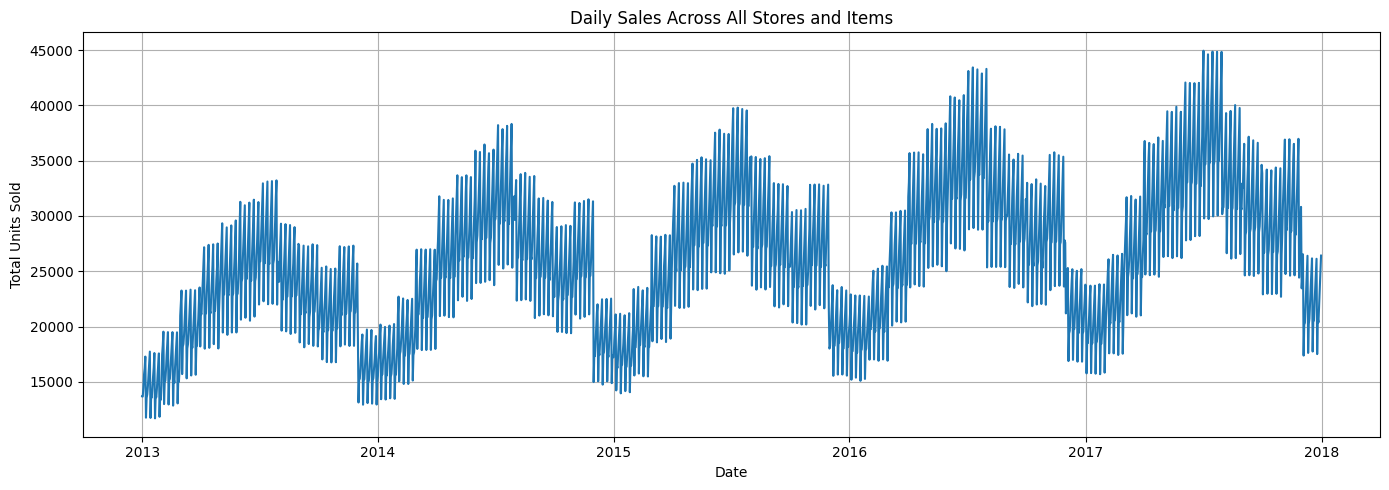

In [7]:
# Convert date to datetime format
df["date"] = pd.to_datetime(df["date"])

# Calculate total daily sales across all stores and items
daily_sales = df.groupby("date")["sales"].sum()

# Plot daily sales
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Daily Sales Across All Stores and Items")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.grid(True)
plt.tight_layout()
plt.show()

Top 10 Best-Selling Items:


,sales
item,
15,1607442
28,1604713
13,1539621
18,1538876
25,1473334
45,1471467
38,1470330
22,1469971
36,1406548


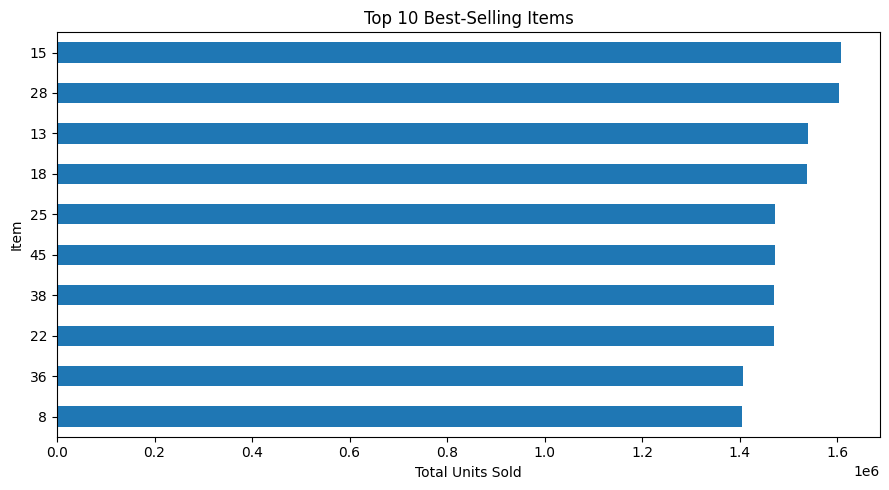

In [8]:
# Calculate total sales for each item
item_sales = df.groupby("item")["sales"].sum()

# Display the top 10 best-selling items
top_items = item_sales.sort_values(ascending=False).head(10)

print("Top 10 Best-Selling Items:")
display(top_items)

# Plot the results
top_items.sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Best-Selling Items")
plt.xlabel("Total Units Sold")
plt.ylabel("Item")
plt.tight_layout()
plt.show()

Baseline Forecast Results
Average forecast per day: 29732.43
MAE: 7342.1
RMSE: 7860.92


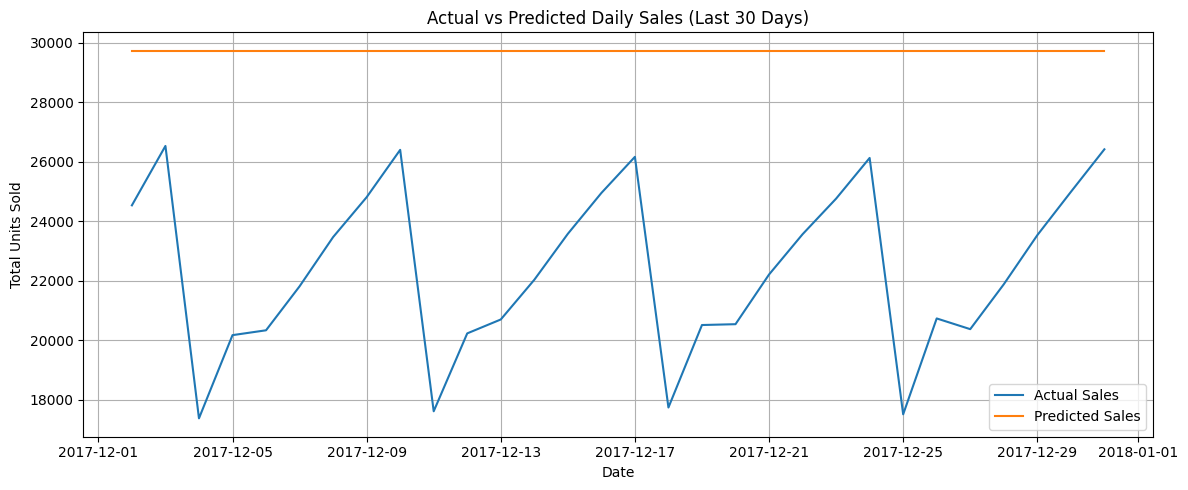

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare total daily sales
daily_sales = df.groupby("date")["sales"].sum().sort_index()

# Use the last 30 days for testing
train = daily_sales.iloc[:-30]
test = daily_sales.iloc[-30:]

# Baseline forecast: average sales from the last 7 training days
forecast_value = train.tail(7).mean()
predictions = np.full(len(test), forecast_value)

# Evaluate the forecast
mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))

print("Baseline Forecast Results")
print("Average forecast per day:", round(forecast_value, 2))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

# Plot actual vs predicted sales
plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, label="Actual Sales")
plt.plot(test.index, predictions, label="Predicted Sales")
plt.title("Actual vs Predicted Daily Sales (Last 30 Days)")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

7-Day Rolling Average Forecast
MAE: 2811.03
RMSE: 3424.52


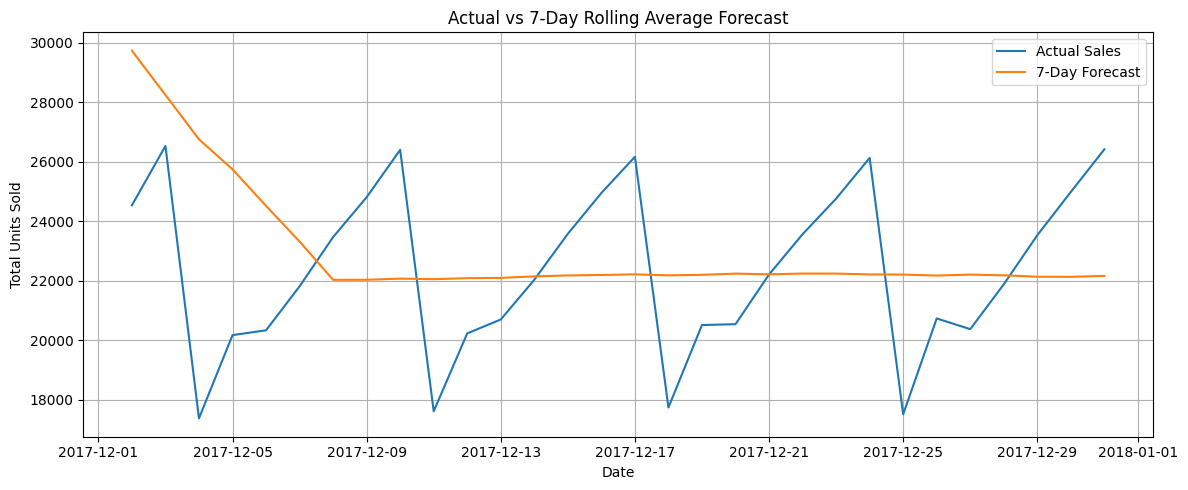

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Total daily sales, sorted by date
daily_sales = df.groupby("date")["sales"].sum().sort_index()

# Keep the final 30 days for testing
train = daily_sales.iloc[:-30]
test = daily_sales.iloc[-30:]

# Rolling 7-day average forecast
history = list(train.values)
predictions_7day = []

for actual in test.values:
    prediction = np.mean(history[-7:])
    predictions_7day.append(prediction)
    history.append(actual)

# Evaluate
mae_7day = mean_absolute_error(test, predictions_7day)
rmse_7day = np.sqrt(
    mean_squared_error(test, predictions_7day))

print("7-Day Rolling Average Forecast")
print("MAE:", round(mae_7day, 2))
print("RMSE:", round(rmse_7day, 2))

# Plot actual and predicted sales
plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, label="Actual Sales")
plt.plot(test.index, predictions_7day, label="7-Day Forecast")
plt.title("Actual vs 7-Day Rolling Average Forecast")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
print("Forecast Model Comparison")
print("-" * 35)
print(f"Baseline MAE: {mae:.2f}")
print(f"7-Day Rolling Average MAE: {mae_7day:.2f}")
print(f"Baseline RMSE: {rmse:.2f}")
print(f"7-Day Rolling Average RMSE: {rmse_7day:.2f}")

if mae_7day < mae:
    print("\nThe rolling average has lower MAE.")
else:
    print("\nThe rolling average did not improve MAE.")

if rmse_7day < rmse:
    print("The rolling average has lower RMSE.")
else:
    print("The rolling average did not improve RMSE.")

Forecast Model Comparison
-----------------------------------
Baseline MAE: 7342.10
7-Day Rolling Average MAE: 2811.03
Baseline RMSE: 7860.92
7-Day Rolling Average RMSE: 3424.52

The rolling average has lower MAE.
The rolling average has lower RMSE.
